# Proyecto Final

## ***Título del Proyecto***: Análisis de las capturas pesqueras marítimas en la República Argentina (2019).

## ***Pregunta de Análisis:*** ¿Cómo se distribuyeron geográficamente y por tipo de flota las capturas pesqueras en Argentina durante 2019, y cuáles fueron las especies predominantes?

## ***Dataset utilizado:*** captura-puerto-flota-2019.csv (cuenta con 3.040 registros y variables sobre fecha, flotas, puertos, provincias, categorías y especies).

## ***Alumna: Andrea Camugino***

##**`* Año: 2026*`**

In [14]:
import pandas as pd

# Cargar el dataset
df = pd.read_csv('/content/drive/MyDrive/herramientas analisis de datos/captura-puerto-flota-2019.csv', encoding='latin1')

# Verificamos que cargó bien mostrando las primeras filas
display(df.head())
print("Dimensiones del dataset:", df.shape)

,fecha,flota,puerto,provincia,provincia_id,departamento,departamento_id,latitud,longitud,categoria,especie,especie_agrupada,captura
0,2019-01,Rada o ría,Bahía Blanca,Buenos Aires,6,Bahía Blanca,6056,-38.789246,-62.272499,Crustáceos,Camarón,otras especies,221363
1,2019-01,Congeladores poteros nacionales,Caleta Olivia / Paula,Santa Cruz,78,Deseado,78014,-46.436049,-67.514904,Moluscos,Calamar Illex,Calamar Illex,101156
2,2019-01,Costeros,Caleta Olivia / Paula,Santa Cruz,78,Deseado,78014,-46.436049,-67.514904,Peces,Merluza hubbsi,Merluza hubbsi S41,4236
3,2019-01,Costeros,Caleta Olivia / Paula,Santa Cruz,78,Deseado,78014,-46.436049,-67.514904,Peces,Rayas nep,Rayas (sin V. Cost),33214
4,2019-01,Fresqueros,Caleta Olivia / Paula,Santa Cruz,78,Deseado,78014,-46.436049,-67.514904,Peces,Merluza hubbsi,Merluza hubbsi S41,2123


Dimensiones del dataset: (3040, 13)


In [15]:
# 1. Estandarizar nombres de columnas a minúsculas y sin espacios
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_', regex=False)
)

# 2. Revisar valores nulos por columna
print("--- VALORES NULOS ---")
print(df.isna().sum())

# 3. Estadísticas descriptivas de la variable numérica principal ('captura')
print("\n--- ESTADÍSTICAS DE CAPTURA (KG) ---")
print(df['captura'].describe())

--- VALORES NULOS ---
fecha                 0
flota                 0
puerto                0
provincia             0
provincia_id          0
departamento          0
departamento_id       0
latitud             216
longitud            216
categoria             0
especie               0
especie_agrupada      0
captura               0
dtype: int64

--- ESTADÍSTICAS DE CAPTURA (KG) ---
count    3.040000e+03
mean     2.232644e+05
std      1.188549e+06
min      1.000000e+00
25%      3.390000e+02
50%      2.680500e+03
75%      2.305425e+04
max      1.862272e+07
Name: captura, dtype: float64


***💡 Interpretación e Insights:***

***1. Concentración geográfica:*** Se observa claramente que la Provincia de Buenos Aires concentra la mayor parte de las capturas pesqueras registradas en 2019 (superando los 540 millones de kilogramos), seguida de lejos por las provincias patagónicas de Chubut y Santa Cruz.

***2. Implicancia analítica:*** Esta diferencia abismal refleja la fuerte centralización de la actividad en puertos clave como el de Mar del Plata, así como la incidencia de las flotas costeras y de rada/ría que operan en la región bonaerense.

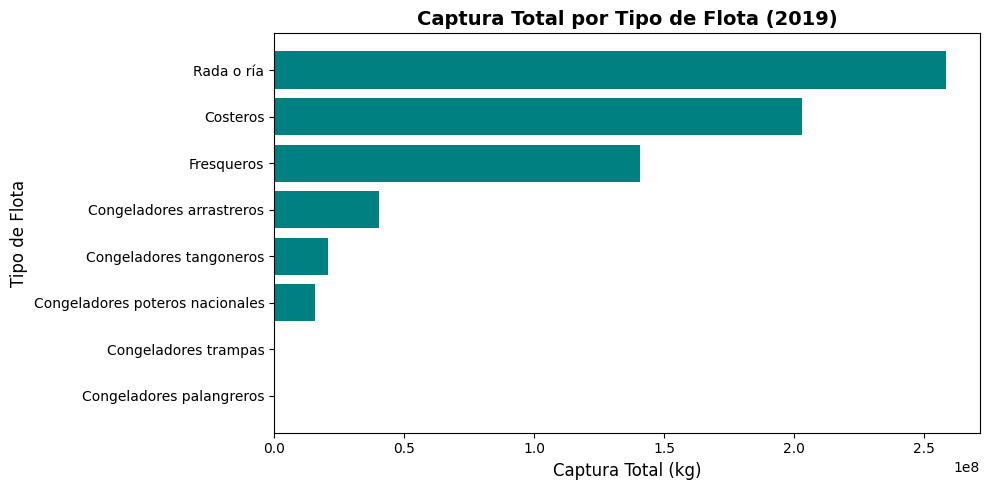

In [16]:
import matplotlib.pyplot as plt

# Agrupar datos por tipo de flota sumando las capturas
flota_captura = df.groupby('flota')['captura'].sum().reset_index()
flota_captura = flota_captura.sort_values(by='captura', ascending=True)

# Crear gráfico de barras horizontales
plt.figure(figsize=(10, 5))
plt.barh(flota_captura['flota'], flota_captura['captura'], color='teal')

plt.title('Captura Total por Tipo de Flota (2019)', fontsize=14, fontweight='bold')
plt.xlabel('Captura Total (kg)', fontsize=12)
plt.ylabel('Tipo de Flota', fontsize=12)
plt.tight_layout()

plt.show()

***💡 Interpretación e Insights:***

1. ***Predominio de flotas artesanales/costeras:*** Las flotas de Rada o ría y los Costeros concentran abrumadoramente el volumen total de captura en kilogramos, superando ampliamente a las flotas de altura o congeladores.

2. ***Diversidad operativa:*** Se observa una marcada diferencia entre la pesca costera/artesanal y las flotas congeladoras industriales (arrastreros, tangoneros y poteros), reflejando la especialización del esfuerzo pesquero según la especie y la zona geográfica.

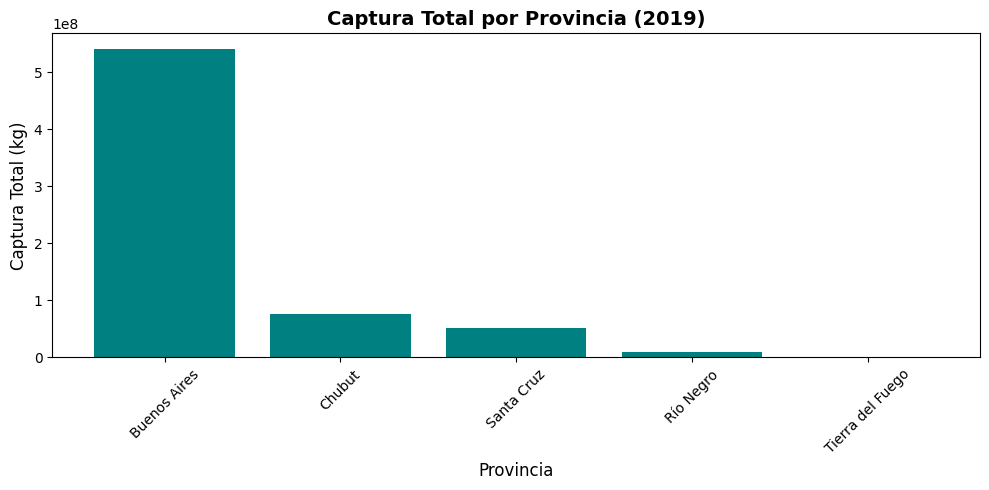

In [17]:
import matplotlib.pyplot as plt

# 1. Agrupar datos por provincia sumando las capturas
provincia_captura = df.groupby('provincia')['captura'].sum().reset_index()
provincia_captura = provincia_captura.sort_values(by='captura', ascending=False)

# 2. Crear gráfico de barras
plt.figure(figsize=(10, 5))
plt.bar(provincia_captura['provincia'], provincia_captura['captura'], color='teal')

plt.title('Captura Total por Provincia (2019)', fontsize=14, fontweight='bold')
plt.xlabel('Provincia', fontsize=12)
plt.ylabel('Captura Total (kg)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

***💡 Interpretación e Insights:***
***1. Fuerte concentración en Buenos Aires:*** La provincia de Buenos Aires encabeza holgadamente el volumen de capturas totales del año 2019, reflejando el peso estratégico de sus puertos y la alta densidad de actividad de las flotas costeras y de rada o ría.

***2.Diferencias regionales en la Patagonia:*** Si bien provincias como Chubut y Santa Cruz concentran importantes volúmenes de pesca (vinculados a la actividad de flotas congeladoras y especies específicas de la región patagónica), se ubican en un segundo escalón en el acumulado total frente al liderazgo bonaerense.

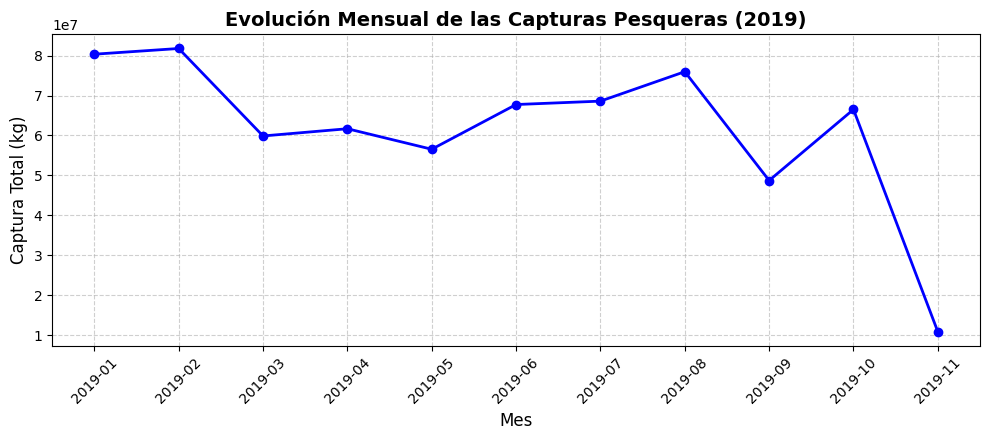

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# Asegurar que la fecha sea tipo datetime y extraer el mes/año o mes
df['fecha'] = pd.to_datetime(df['fecha'], errors='coerce')
df['mes'] = df['fecha'].dt.to_period('M')

# Agrupar por mes sumando las capturas
ventas_mes = df.groupby('mes')['captura'].sum().reset_index()
ventas_mes['mes_str'] = ventas_mes['mes'].astype(str)

# Crear gráfico de línea temporal
plt.figure(figsize=(10, 4.5))
plt.plot(ventas_mes['mes_str'], ventas_mes['captura'], marker='o', color='b', linewidth=2)

plt.title('Evolución Mensual de las Capturas Pesqueras (2019)', fontsize=14, fontweight='bold')
plt.xlabel('Mes', fontsize=12)
plt.ylabel('Captura Total (kg)', fontsize=12)
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()

***💡 Interpretación e Insights:***

***1. Estacionalidad y Picos de Captura:*** Se observa que los mayores volúmenes de captura se concentran en los primeros meses del año (enero y febrero) y presentan otro repunte importante hacia el mes de agosto, superando los 80 millones de kilogramos en esos períodos.

***2. Variabilidad y Caída Estacional:*** Hacia el tramo final del año se registra una marcada disminución en el volumen total de descargas, reflejando el impacto de los ciclos biológicos de las especies y las vedas o temporadas de pesca.